# Medical Insurance Charges Prediction – Model Development

## Project objective
Build and evaluate regression models that estimate medical insurance charges from customer attributes. This notebook contains the experiments carried out during model development, including a simple baseline, multiple-feature regression, polynomial features, Ridge regularization, hyperparameter tuning, diagnostics, and model saving.

## Generative AI in the workflow
Generative AI supported the learning and development process by helping explain Python and scikit-learn concepts, troubleshoot errors, interpret model-evaluation techniques, and organize documentation. The predictive model is trained by scikit-learn on the dataset; Generative AI is not the prediction engine.

> Important: This notebook contains multiple experiments and repeated training cells. Run cells in order within a fresh kernel. Before relying on the final model, verify that the data preprocessing used here matches the preprocessing in `app.py`.

In [2]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

## 1. Load the prepared dataset

Load the cleaned dataset produced by the data-wrangling stage. The target variable for this project is `charges`.

In [3]:
df = pd.read_csv("updated_medical_insurance_dataset.csv")

## 2. Simple baseline: smoker as the only predictor

This first experiment uses only the `smoker` feature to establish a simple baseline. It helps illustrate how one predictor can be used in a regression model. It is not expected to capture all factors associated with insurance charges.

In [4]:
X = df[['smoker']]
y = df['charges']

In [5]:
lr = LinearRegression()

lr.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[23805.27]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['smoker']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8418
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [6]:
y_pred = lr.predict(X)
r2 = r2_score(y, y_pred)

print("R2 Score:", r2)

R2 Score: 0.6221791718835359


## 3. Train/test split for the baseline

The data is divided into training and testing subsets. The model is fitted using the training subset and evaluated on held-out test observations. `random_state=42` makes the split reproducible.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

print("Test R2 Score:", r2_score(y_test, y_pred))

Test R2 Score: 0.5991358029440947


## 4. Prepare features and target for multiple regression

`X` contains the independent variables (predictors), while `y` contains the target variable (`charges`). Categorical variables must be encoded before a regression estimator can use them.

In [8]:
# Independent variables: All columns except charges
X = df.drop('charges', axis=1)

# Dependent variable
y = df['charges']

## 5. Encode categorical features

One-hot encoding converts category labels into numeric indicator columns. `drop_first=True` removes one category per encoded field to reduce redundant columns in linear models.

In [9]:
X = pd.get_dummies(
    X,
    columns=['gender', 'smoker', 'region'],
    drop_first=True,
    dtype=int
)

## 6. Split the encoded dataset

The encoded predictors and target are split into training and testing subsets using the same 80:20 proportion and fixed random seed.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 7. Check missing values

Missing-value counts are checked before fitting models. Missing values should be handled using a method appropriate to each feature and applied without leaking information from the test set into training.

In [18]:
print(df.isnull().sum())

age               4
gender            0
bmi               0
no_of_children    0
smoker            0
region            0
charges           0
dtype: int64


In [20]:
df['age'] = df['age'].fillna(df['age'].median())

In [22]:
print(df.isnull().sum())

age               0
gender            0
bmi               0
no_of_children    0
smoker            0
region            0
charges           0
dtype: int64


## 8. Multiple Linear Regression experiment

This experiment fits a linear regression model using the available predictors. The test-set R² score summarizes the proportion of target variation explained by the model on held-out data.

In [24]:
X = df.drop('charges', axis=1)
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.7395785004918456


In [26]:
X = df.drop('charges', axis=1)
y = df['charges']

In [28]:
print(df.head(10))

    age  gender     bmi  no_of_children  smoker  region      charges
0  19.0       1  27.900               0       1       3  16884.92400
1  18.0       2  33.770               1       0       4   1725.55230
2  28.0       2  33.000               3       0       4   4449.46200
3  33.0       2  22.705               0       0       1  21984.47061
4  32.0       2  28.880               0       0       1   3866.85520
5  31.0       1  25.740               0       0       4   3756.62160
6  46.0       1  33.440               1       0       4   8240.58960
7  37.0       1  27.740               3       0       1   7281.50560
8  37.0       2  29.830               2       0       2   6406.41070
9  60.0       1  25.840               0       0       1  28923.13692


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2772 non-null   float64
 1   gender          2772 non-null   int64  
 2   bmi             2772 non-null   float64
 3   no_of_children  2772 non-null   int64  
 4   smoker          2772 non-null   int64  
 5   region          2772 non-null   int64  
 6   charges         2772 non-null   float64
dtypes: float64(3), int64(4)
memory usage: 151.7 KB


## 9. Preprocessing pipeline with polynomial numerical features

This experiment separates numerical and categorical preprocessing. Numerical features are scaled and expanded with degree-two polynomial terms; categorical features are one-hot encoded. A `ColumnTransformer` applies the appropriate transformations, and a pipeline connects preprocessing to linear regression.

Pipelines help keep transformations consistent between training and prediction and reduce the risk of fitting preprocessing on test data.

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score, mean_squared_error

In [34]:
# Separate numerical and categorical features
numeric_features = ['age', 'bmi', 'no_of_children']
categorical_features = ['gender', 'smoker', 'region']

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

# Complete training pipeline
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', LinearRegression())
])

## 10. Fit and evaluate the preprocessing pipeline

The pipeline is trained on the training subset. Predictions are then generated for the test subset and evaluated using regression metrics.

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [38]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','gender','bmi','no_of_children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concaten

In [40]:
y_pred = model.predict(X_test)

In [42]:
r2 = r2_score(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

print("R2 Score:", r2)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", mse ** 0.5)

R2 Score: 0.7444913970108604
Mean Squared Error: 39215704.953494646
Root Mean Squared Error: 6262.244402248658


## 11. Re-establish the train/test split for subsequent experiments

This cell defines the predictors and target again and creates the split used in the following Ridge and polynomial-regression experiments. Keep the split consistent when comparing models.

In [44]:
from sklearn.model_selection import train_test_split

X = df.drop('charges', axis=1)
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

In [46]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (2217, 6)
Testing features: (555, 6)
Training target: (2217,)
Testing target: (555,)


In [48]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## 12. Ridge Regression

Ridge Regression adds an L2 penalty to the linear regression objective. The `alpha` parameter controls the strength of regularization: larger values apply stronger coefficient shrinkage.

In [50]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

In [52]:
RidgeModel = Ridge(alpha=0.1)

In [54]:
RidgeModel.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [56]:
y_pred = RidgeModel.predict(X_test)

In [58]:
R2 = r2_score(y_test, y_pred)

print("R2 Score:", R2)

R2 Score: 0.7395716457007178


## 13. Polynomial features with Ridge Regression

PolynomialFeatures expands the predictors with interaction and higher-order terms. Ridge regularization can help control coefficient size when this expanded feature space becomes complex. The transformation is fitted on training data and then applied to test data.

In [60]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

In [62]:
pr = PolynomialFeatures(degree=2)

X_train_pr = pr.fit_transform(X_train)
X_test_pr = pr.transform(X_test)

In [64]:
RidgeModel = Ridge(alpha=0.1)

RidgeModel.fit(X_train_pr, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [66]:
y_pred = RidgeModel.predict(X_test_pr)

In [68]:
R2 = r2_score(y_test, y_pred)

print("R2 Score:", R2)

R2 Score: 0.8339389435500972


## 14. Compare baseline and regression experiments

This section prepares predictions from the models for comparison. A fair comparison requires each model's predictions and actual target values to refer to the same test observations. Confirm that the feature representation used by each model matches the data supplied to it.

In [74]:
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_squared_error
import pandas as pd

# 1. Multiple Linear Regression
y_pred_multiple = lr.predict(X_test)

# 2. Polynomial Ridge Regression
y_pred_poly_ridge = RidgeModel.predict(X_test_pr)

## 15. Train a simple smoker-only model for comparison

A separate train/test split is created for the smoker-only baseline. The fixed random state and same row order are intended to make the split reproducible.

In [77]:
X_smoker = df[['smoker']]
y = df['charges']

X_smoker_train, X_smoker_test, y_smoker_train, y_smoker_test = train_test_split(
    X_smoker, y, test_size=0.2, random_state=42
)

In [79]:
simple_lr = LinearRegression()

simple_lr.fit(X_smoker_train, y_smoker_train)

y_pred_linear = simple_lr.predict(X_smoker_test)

## 16. Train a multiple regression model on encoded features

The categorical predictors are converted to indicator columns before training. The resulting encoded feature matrix is split into training and test subsets, and the model is fitted on the training data.

In [81]:
X = df.drop('charges', axis=1)

X_encoded = pd.get_dummies(
    X,
    columns=['gender', 'region'],
    drop_first=True,
    dtype=int
)

X_train_encoded, X_test_encoded, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

multiple_lr = LinearRegression()

multiple_lr.fit(X_train_encoded, y_train)

y_pred_multiple = multiple_lr.predict(X_test_encoded)

In [83]:
y_pred_poly_ridge = RidgeModel.predict(X_test_pr)

## 17. Compare model performance

The table compares R² and RMSE for the simple, multiple, and polynomial Ridge models. Interpret the metrics together: higher R² and lower RMSE generally indicate better test-set performance, provided all models were evaluated on equivalent observations.

In [85]:
results = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Polynomial Ridge Regression'
    ],
    'R2 Score': [
        r2_score(y_smoker_test, y_pred_linear),
        r2_score(y_test, y_pred_multiple),
        r2_score(y_test, y_pred_poly_ridge)
    ],
    'RMSE': [
        mean_squared_error(y_smoker_test, y_pred_linear) ** 0.5,
        mean_squared_error(y_test, y_pred_multiple) ** 0.5,
        mean_squared_error(y_test, y_pred_poly_ridge) ** 0.5
    ]
})

print(results)

                         Model  R2 Score         RMSE
0     Simple Linear Regression  0.599136  7843.788668
1   Multiple Linear Regression  0.739817  6319.271679
2  Polynomial Ridge Regression  0.833939  5048.485901


## 18. Detailed regression metrics

MAE measures the average absolute prediction error. MSE is the average squared error, and RMSE is its square root, expressed in the same units as the target. R² measures the proportion of target variance explained by the model.

In [87]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred_poly_ridge)
mse = mean_squared_error(y_test, y_pred_poly_ridge)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred_poly_ridge)

print("R2 Score:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

R2 Score: 0.8339389435500972
MAE: 2928.4754837660694
MSE: 25487209.893601134
RMSE: 5048.48590109957


In [89]:
residuals = y_test - y_pred_poly_ridge

print(residuals.head(10))

1106    -688.042157
1321   -4709.248498
2313   -1410.560418
2274   -1002.548884
1432   -2554.837632
2240   -1011.839497
965    -1662.263609
2626   -3061.068209
2134   -1627.555627
2296   -2198.359057
Name: charges, dtype: float64


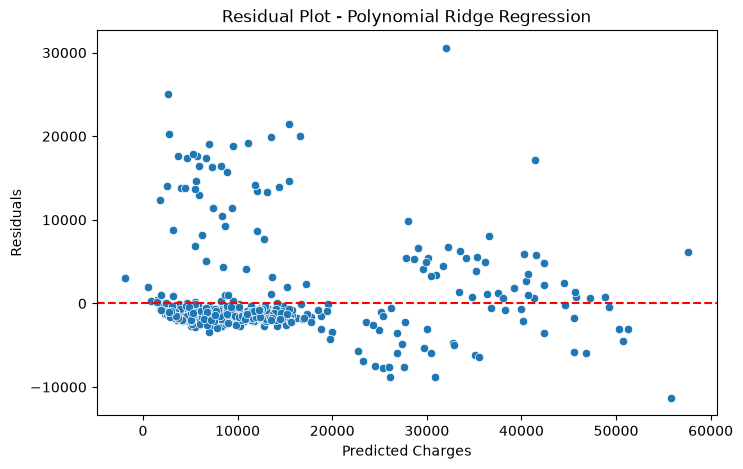

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_pred_poly_ridge, y=residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")
plt.title("Residual Plot - Polynomial Ridge Regression")

plt.show()

In [93]:
comparison = pd.DataFrame({
    'Actual Charges': y_test,
    'Predicted Charges': y_pred_poly_ridge
})

print(comparison.head(10))

      Actual Charges  Predicted Charges
1106      8988.15875        9676.200907
1321     28101.33305       32810.581548
2313     12032.32600       13442.886418
2274      1682.59700        2685.145884
1432      3393.35635        5948.193982
2240     24106.91255       25118.752047
965       4746.34400        6408.607609
2626     47269.85400       50330.922209
2134      8556.90700       10184.462627
2296      2639.04290        4837.401957


## 19. Hyperparameter tuning with GridSearchCV

GridSearchCV evaluates combinations of polynomial degree and Ridge `alpha` using cross-validation on the training data. The test set is held back for final evaluation rather than model selection.

In [95]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error

### 19.1 Define the modeling pipeline

The pipeline expands features with polynomial terms, scales the resulting features, and fits Ridge Regression. Keeping these steps in one pipeline ensures that each cross-validation fold fits its transformations only on that fold's training portion.

In [97]:
pipeline = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

### 19.2 Define the hyperparameter search space

The grid tests polynomial degrees 1, 2, and 3 and several Ridge regularization strengths. These are candidate values, not guaranteed optimal settings.

In [99]:
param_grid = {
    'poly__degree': [1, 2, 3],
    'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100]
}

### 19.3 Configure cross-validation

Five-fold cross-validation and R² scoring are used to compare candidate parameter combinations. Parallel execution is enabled with `n_jobs=-1`.

In [101]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

### 19.4 Run the grid search

The search is fitted using training data only. The best combination is selected based on mean cross-validation R².

In [103]:
grid_search.fit(X_train_encoded, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'poly__degree': [1, 2, ...], 'ridge__alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of infor

In [105]:
print("Best Parameters:", grid_search.best_params_)

print("Best Cross-Validation R2:",
      grid_search.best_score_)

Best Parameters: {'poly__degree': 2, 'ridge__alpha': 1}
Best Cross-Validation R2: 0.8443492311994245


## 20. Evaluate the best model on the held-out test set

The best estimator is evaluated once on the test data. Report the resulting R² and RMSE as measured outputs; do not substitute expected or example values.

In [107]:
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test_encoded)

print("Test R2:", r2_score(y_test, y_pred_best))

rmse = mean_squared_error(y_test, y_pred_best) ** 0.5

print("Test RMSE:", rmse)

Test R2: 0.8358900291172806
Test RMSE: 5018.740420983876


## 21. Learning curve analysis

A learning curve compares training and cross-validation performance as the amount of training data increases. It can help diagnose whether a model may be overfitting or underfitting.

In [109]:
import matplotlib.pyplot as plt

from sklearn.model_selection import learning_curve

In [111]:
best_model = grid_search.best_estimator_ 

### 21.1 Calculate learning-curve scores

The learning curve uses cross-validation on the training subset. The held-out test set is not used in this diagnostic.

In [113]:
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=best_model,
    X=X_train_encoded,
    y=y_train,
    cv=5,
    scoring='r2',
    train_sizes=[0.1, 0.3, 0.5, 0.7, 1.0],
    n_jobs=-1
)

In [115]:
train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

print("Training Scores:", train_mean)
print("Validation Scores:", validation_mean)

Training Scores: [0.87001583 0.85587872 0.86325498 0.85610271 0.85019217]
Validation Scores: [0.7972387  0.83551825 0.84117565 0.84375701 0.84443231]


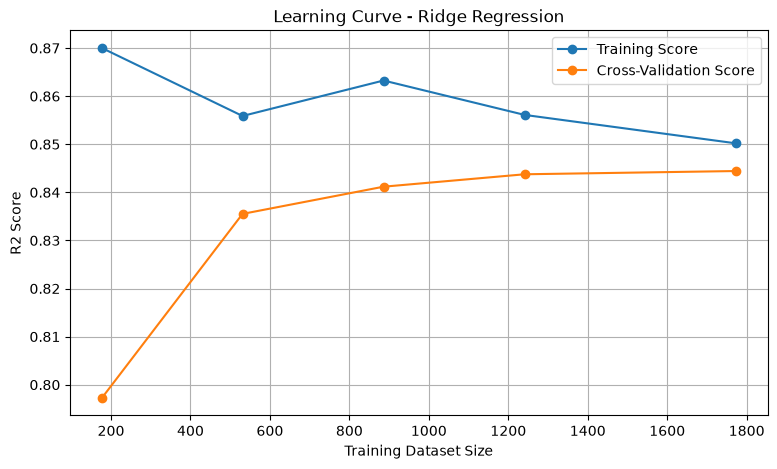

In [117]:
plt.figure(figsize=(9, 5))

plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Training Score'
)

plt.plot(
    train_sizes,
    validation_mean,
    marker='o',
    label='Cross-Validation Score'
)

plt.xlabel("Training Dataset Size")
plt.ylabel("R2 Score")
plt.title("Learning Curve - Ridge Regression")

plt.legend()
plt.grid(True)

plt.show()

## 22. Inspect predictions and residuals

Compare actual and predicted charges to understand individual prediction differences. Residuals are calculated as actual minus predicted values; positive residuals mean the model underpredicted, while negative residuals mean it overpredicted.

In [119]:
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test_encoded)

In [121]:
import pandas as pd

comparison = pd.DataFrame({
    'Actual Charges': y_test.values,
    'Predicted Charges': y_pred_best
})

comparison['Difference'] = (
    comparison['Actual Charges'] -
    comparison['Predicted Charges']
)

print(comparison.head(10))

   Actual Charges  Predicted Charges   Difference
0      8988.15875        9538.530593  -550.371843
1     28101.33305       33006.360250 -4905.027200
2     12032.32600       13018.236339  -985.910339
3      1682.59700        1717.946347   -35.349347
4      3393.35635        7268.464597 -3875.108247
5     24106.91255       25631.277981 -1524.365431
6      4746.34400        5529.068926  -782.724926
7     47269.85400       49970.759040 -2700.905040
8      8556.90700        9649.342510 -1092.435510
9      2639.04290        4744.147399 -2105.104499


## 23. Actual versus predicted visualization

Points close to the diagonal reference line indicate predictions close to actual values. Systematic departures from the line can reveal patterns in model error.

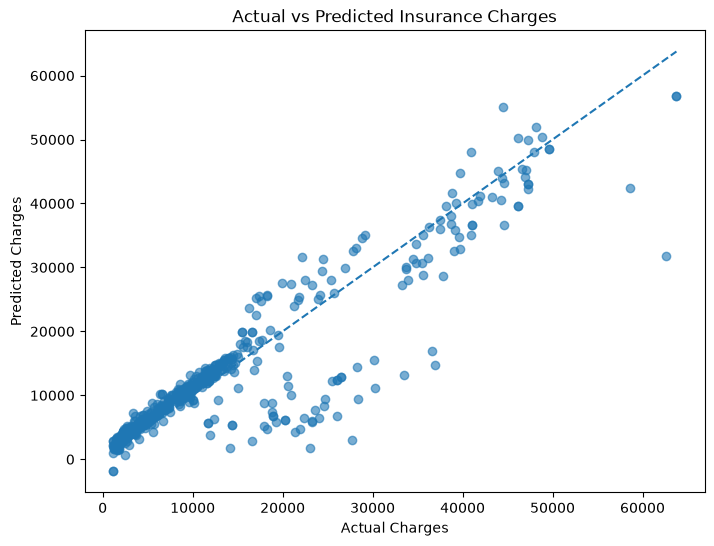

In [123]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_best, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Insurance Charges')

plt.show()

## 24. Final test-set metrics

This cell reports the main regression metrics for the selected model. Use these measured values in your README and project presentation.

In [125]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("R2 Score:", r2_score(y_test, y_pred_best))

print("MAE:", mean_absolute_error(y_test, y_pred_best))

print("RMSE:", mean_squared_error(y_test, y_pred_best) ** 0.5)

R2 Score: 0.8358900291172806
MAE: 2912.4793274188505
RMSE: 5018.740420983876


## 25. Residual diagnostics

Residual analysis helps check whether errors are centered around zero and whether their spread changes across predictions. Patterns in residuals may indicate that the model does not capture all structure in the data.

In [127]:
residuals = y_test - y_pred_best

print(residuals.head(10))

1106    -550.371843
1321   -4905.027200
2313    -985.910339
2274     -35.349347
1432   -3875.108247
2240   -1524.365431
965     -782.724926
2626   -2700.905040
2134   -1092.435510
2296   -2105.104499
Name: charges, dtype: float64


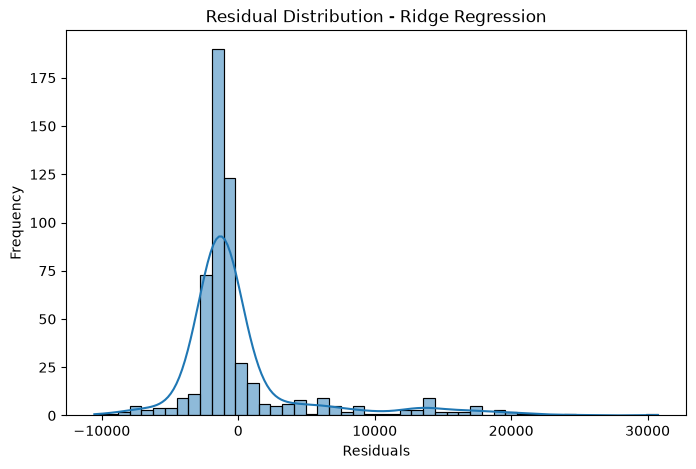

In [129]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Ridge Regression")

plt.show()

## 26. Q-Q plot of residuals

The Q-Q plot compares the residual distribution with a theoretical normal distribution. Strong deviations from the reference line suggest departures from normality. Normal residuals are not required for prediction itself, but the diagnostic can matter for some classical regression-inference assumptions.

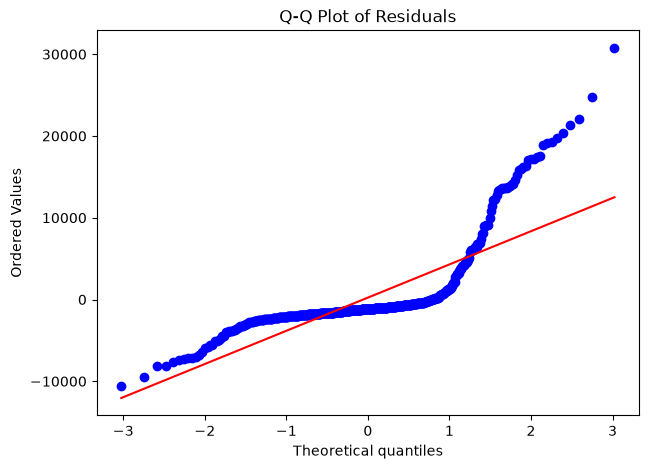

In [131]:
import scipy.stats as stats

plt.figure(figsize=(7, 5))

stats.probplot(residuals, dist="norm", plot=plt)

plt.title("Q-Q Plot of Residuals")

plt.show()

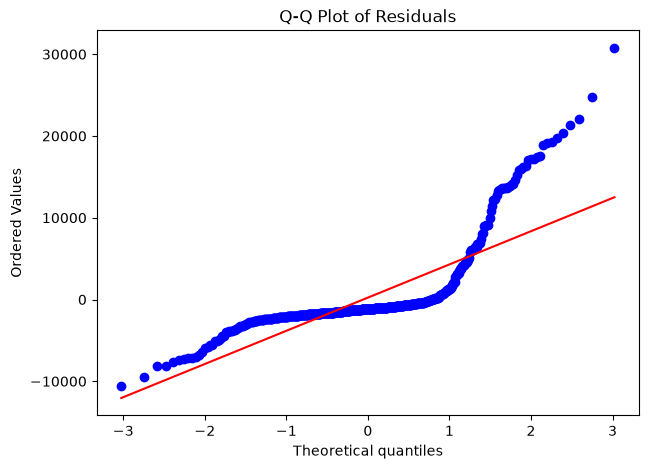

In [133]:
import scipy.stats as stats

plt.figure(figsize=(7, 5))

stats.probplot(residuals, dist="norm", plot=plt)

plt.title("Q-Q Plot of Residuals")

plt.show()

## 27. Mean residual

The mean residual provides a quick check for average overprediction or underprediction. A value near zero does not by itself guarantee that the model is well calibrated across all ranges.

In [135]:
print("Mean Residual:", residuals.mean())

Mean Residual: 230.30138212402503


## 28. Consolidated model comparison

The comparison table collects R², MAE, and RMSE for the selected model experiments. Check that each prediction array is paired with the matching actual target observations before interpreting the table.

In [137]:
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models = {
    'Simple Linear Regression': (y_smoker_test, y_pred_linear),
    'Multiple Linear Regression': (y_test, y_pred_multiple),
    'Polynomial Ridge Regression': (y_test, y_pred_best)
}

results = []

for name, (actual, predicted) in models.items():

    results.append({
        'Model': name,
        'R2 Score': r2_score(actual, predicted),
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': mean_squared_error(actual, predicted) ** 0.5
    })

comparison_df = pd.DataFrame(results)

print(comparison_df)

                         Model  R2 Score          MAE         RMSE
0     Simple Linear Regression  0.599136  5927.922481  7843.788668
1   Multiple Linear Regression  0.739817  4160.247975  6319.271679
2  Polynomial Ridge Regression  0.835890  2912.479327  5018.740421


## 29. Save the selected model

The fitted best estimator is serialized with joblib so that it can be loaded by the Streamlit application. Only load pickle/joblib files from trusted sources.

In [139]:
import joblib

joblib.dump(best_model, 'insurance_ridge_model.pkl')

['insurance_ridge_model.pkl']

## 30. Reload the saved model

Reloading the model checks that the serialized file can be opened in the current Python environment.

In [141]:
loaded_model = joblib.load('insurance_ridge_model.pkl')

## 31. Test predictions from the reloaded model

A small sample of test features is passed to the reloaded model. The input columns and preprocessing must match the representation used when the model was trained.

In [143]:
sample_prediction = loaded_model.predict(X_test_encoded.iloc[:5])

print(sample_prediction)

[ 9538.53059273 33006.36024978 13018.23633929  1717.94634665
  7268.46459691]


In [145]:
import joblib

joblib.dump(best_model, 'insurance_ridge_model.pkl')

['insurance_ridge_model.pkl']

## 32. Save the expected feature-column order

The feature names and their order are saved for use by the Streamlit app. The app must create the same columns with the same encoding rules before making predictions.

In [147]:
joblib.dump(
    X_train_encoded.columns.tolist(),
    'feature_columns.pkl'
)

['feature_columns.pkl']

2026-11-15 01:31:36.441 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-15 01:31:37.665 
  command:

    streamlit run C:\Users\sauno\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-15 01:31:37.665 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-15 01:31:37.667 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-15 01:31:37.669 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-15 01:31:37.673 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-15 01:31:37.674 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-15 01:31:37.676 Thre